In [1]:
!pip install -q opendatasets legacy-cgi
import opendatasets as od

In [2]:
od.download("https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset/croissant/download")

Dataset URL: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset


100%|██████████| 67.4k/67.4k [00:00<00:00, 18.4MB/s]

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("/content/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv")

In [8]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [9]:
df.shape[0]

5110

In [10]:
df.shape[1]

12

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [12]:
missing = pd.DataFrame({
    "Количество": df.isna().sum(),
    "Доля, %": (df.isna().mean() * 100).round(2)
})

In [14]:
missing.sort_values("Количество", ascending=False)

,Количество,"Доля, %"
bmi,201,3.93
id,0,0.00
age,0,0.00
gender,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
work_type,0,0.00
ever_married,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00


In [15]:
unknown = df["smoking_status"].eq("Unknown")

In [17]:
unknown.sum()

np.int64(1544)

In [18]:
round(unknown.mean() * 100, 2)

np.float64(30.22)

In [19]:
bmi_missing = (df.assign(bmi_missing=df["bmi"].isna()).groupby("stroke")["bmi_missing"].agg(Всего="size", Пропусков="sum", Доля="mean"))
bmi_missing["Доля, %"] = (bmi_missing.pop("Доля") * 100).round(2)

In [20]:
bmi_missing

,Всего,Пропусков,"Доля, %"
stroke,,,
0,4861,161,3.31
1,249,40,16.06


In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df["id"].duplicated().sum()

np.int64(0)

In [23]:
df.drop(columns="id").duplicated().sum()

np.int64(0)

In [27]:
df.nunique()

,0
id,5110
gender,3
age,104
hypertension,2
heart_disease,2
ever_married,2
work_type,5
Residence_type,2
avg_glucose_level,3979
bmi,418


In [28]:
df["gender"].value_counts()

,count
gender,
Female,2994
Male,2115
Other,1


In [29]:
df["work_type"].value_counts()

,count
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22


In [30]:
df["stroke"].value_counts()

,count
stroke,
0,4861
1,249


In [31]:
(df["stroke"].value_counts(normalize=True) * 100).round(2)

,proportion
stroke,
0,95.13
1,4.87


<Axes: xlabel='stroke'>

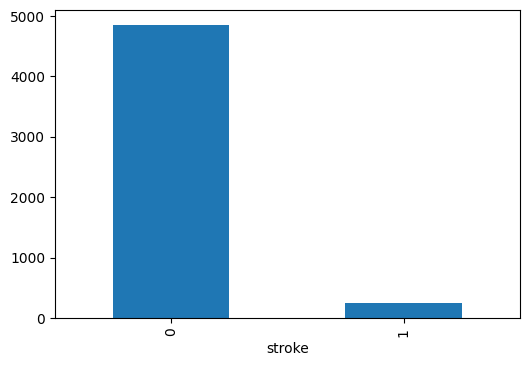

In [33]:
df["stroke"].value_counts().sort_index().plot(kind="bar", figsize=(6, 4))

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'avg_glucose_level'}>,
        <Axes: title={'center': 'bmi'}>]], dtype=object)

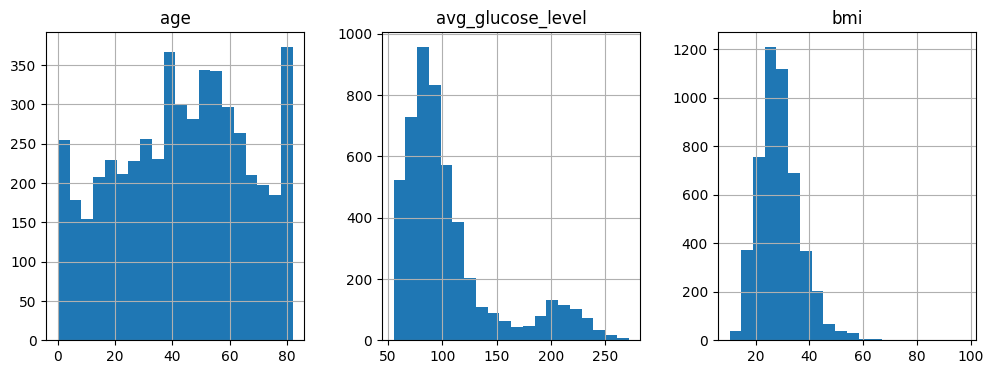

In [34]:
df[["age", "avg_glucose_level", "bmi"]].hist(bins=20, figsize=(12, 4), layout=(1, 3))

<Axes: >

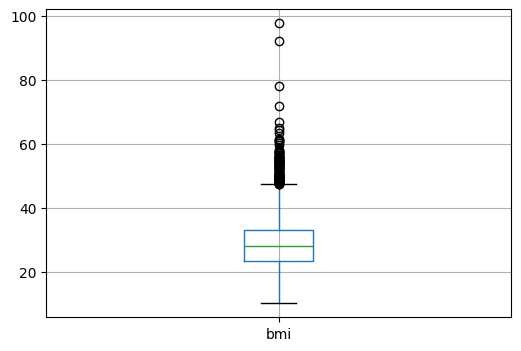

In [35]:
df.boxplot(column="bmi", figsize=(6, 4))

In [36]:
df_prepared = df[df["gender"] != "Other"].copy()

In [37]:
df_prepared["gender"].value_counts()

,count
gender,
Female,2994
Male,2115


In [38]:
df_prepared["bmi_missing"] = df_prepared["bmi"].isna()
median_bmi = df_prepared["bmi"].median()
df_prepared["bmi"] = df_prepared["bmi"].fillna(median_bmi)

In [39]:
median_bmi

28.1

In [40]:
df_prepared["bmi_missing"].sum()

np.int64(201)

In [41]:
df_prepared["bmi"].isna().sum()

np.int64(0)